# Feature analysis: data types, correlation, and why each feature is (or isn't) in the model

Companion to `data-collection/eda_heatmaps.ipynb` (raw descriptive stats across the whole DB)
and `model_comparison.ipynb`/`model_comparison_robust.ipynb` (which model *family* wins). This
notebook is about the specific `MODEL_FEATURES` the shipped `batting_wpa`/`bowling_wpa`
regressors actually consume (`criiq_models/features/schema.py`): their data types, how much is
missing, how they correlate with each other and with the targets, why each category is in the
model, and — reproduced live, not just quoted — why the candidate features that were tried and
rejected didn't make the cut. The last section covers the *other* trained component, the
empirical win-probability model, the same way.

Everything below runs against the real training table (`features/historical.py::build_training_table`),
the same function `criiq_models.cli train`/`backtest` use in production.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath("."))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

from criiq_models.db import connect
from criiq_models.config import SETTINGS
from criiq_models.features.historical import build_training_table
from criiq_models.features.schema import NUMERIC_FEATURES, CATEGORICAL_FEATURES, MODEL_FEATURES, TARGETS
from criiq_models.recommend.train import _make_model, _clip_target

conn = connect()
FMT = "T20"

tables = {g: build_training_table(conn, FMT, g) for g in ("female", "male")}
for g, t in tables.items():
    print(f"{g}: {len(t)} rows, {t['date'].min()} to {t['date'].max()}")

female: 40969 rows, 2009-06-18 to 2026-06-15
male: 71876 rows, 2005-02-17 to 2026-06-14


## 1. Data types

What the model actually sees, column by column — every `NUMERIC_FEATURES` entry is a float, `role_bucket` is the one categorical column (one-hot encoded inside the `Pipeline`/`ColumnTransformer` before the tree models see it — see `recommend/train.py::_rf_pipeline`), and the two targets are floats.

In [2]:
dtype_rows = []
for col in MODEL_FEATURES + TARGETS:
    kind = "categorical" if col in CATEGORICAL_FEATURES else ("target" if col in TARGETS else "numeric")
    dtype_rows.append({"feature": col, "kind": kind, "dtype": str(tables["female"][col].dtype)})
dtype_df = pd.DataFrame(dtype_rows)
dtype_df

,feature,kind,dtype
0,career_matches,numeric,int64
1,career_bat_contribution_pct,numeric,float64
2,career_bowl_contribution_pct,numeric,float64
3,career_bat_sr,numeric,float64
4,career_bowl_economy,numeric,float64
5,career_batting_wpa,numeric,float64
6,career_bowling_wpa,numeric,float64
7,career_bowl_wickets_per_match,numeric,float64
8,form_bat_contribution_pct,numeric,float64
9,form_bowl_contribution_pct,numeric,float64


## 2. Missingness, by feature (both genders)

None of this is fed to the model raw: `SimpleImputer(strategy="median")` inside the `Pipeline` handles the RandomForest/RF-half of the VotingRegressor, and `HistGradientBoostingRegressor` (the other half, bowling_wpa only) natively handles missing values and the `role_bucket` category dtype without any encoding step at all (`categorical_features="from_dtype"`). The pattern below matches what `features/current.py`'s docstring already expects: `vs_opp_*`/`venue_*`/`domestic_form_*` are the sparsest (a player with 0 prior matches vs this opponent/at this venue/in a domestic league has nothing to average), which is exactly why those three groups get `shrink_series()` toward the career baseline rather than being left as raw, wildly-unstable small-sample means.

In [3]:
miss_rows = []
for g, t in tables.items():
    for col in NUMERIC_FEATURES + TARGETS:
        miss_rows.append({"gender": g, "feature": col,
                           "pct_missing": round(100 * pd.to_numeric(t[col], errors="coerce").isna().mean(), 1)})
miss_df = pd.DataFrame(miss_rows).pivot(index="feature", columns="gender", values="pct_missing")
miss_df.loc[NUMERIC_FEATURES + TARGETS].style.background_gradient(cmap="Reds", vmin=0, vmax=100).format("{:.1f}%")

gender,female,male
feature,,
career_matches,0.0%,0.0%
career_bat_contribution_pct,10.0%,9.4%
career_bowl_contribution_pct,28.5%,30.8%
career_bat_sr,10.0%,9.4%
career_bowl_economy,28.3%,30.6%
career_batting_wpa,6.8%,8.2%
career_bowling_wpa,6.8%,8.2%
career_bowl_wickets_per_match,28.3%,30.6%
form_bat_contribution_pct,10.1%,9.5%


## 3. Feature correlation heatmap

Two things worth reading off this: (a) do any of the model's own *inputs* move together strongly (multicollinearity) — a real concern for linear models, a much smaller one for the tree ensembles actually shipped here, since a Random Forest/HistGB split just picks whichever correlated feature is locally more informative rather than being confused by the collinearity the way a linear regression's coefficients would be; and (b) does any single feature correlate strongly with `batting_wpa`/`bowling_wpa` on its own — the last two rows/columns. Diverging blue (negative) / red (positive) around a neutral gray zero, matching this session's dataviz-heatmap convention.

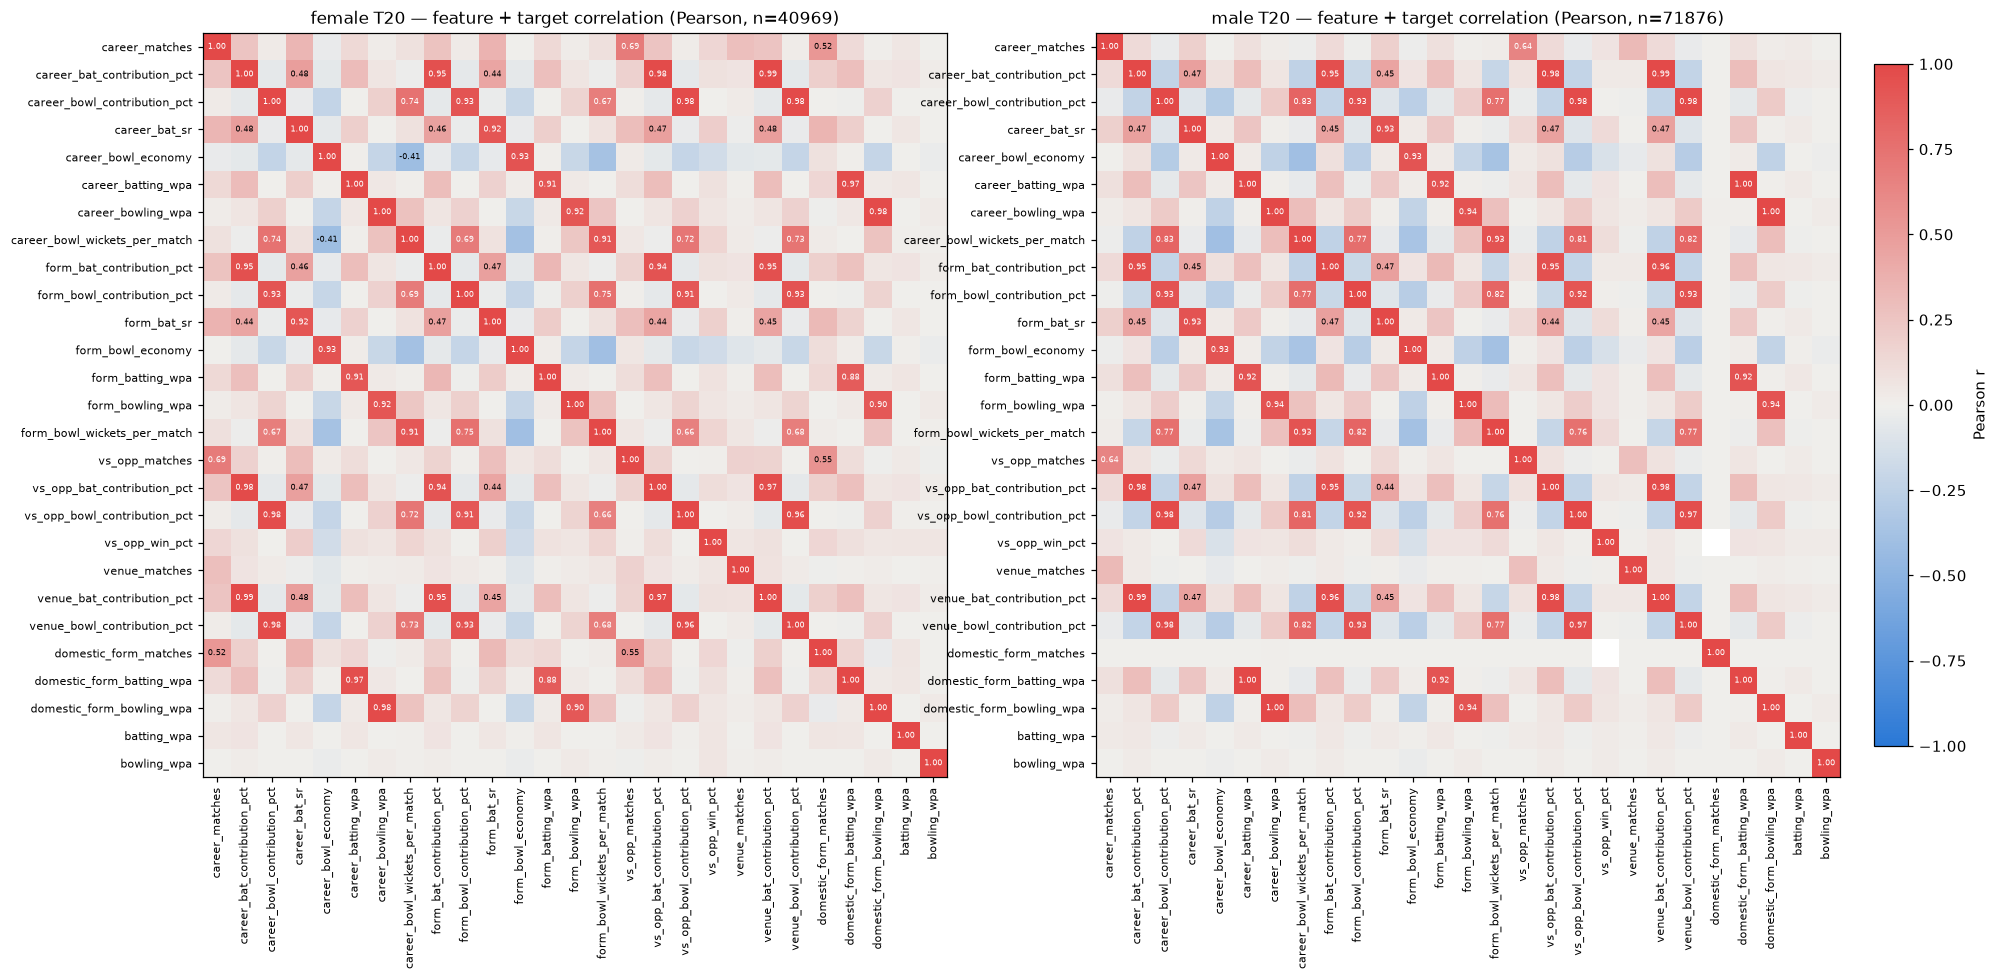

In [4]:
_DIVERGING = LinearSegmentedColormap.from_list(
    "criiq_diverging", ["#2a78d6", "#f0efec", "#e34948"])  # blue -> neutral gray -> red

def plot_corr(ax, corr, title):
    im = ax.imshow(corr.values, cmap=_DIVERGING, vmin=-1, vmax=1)
    ax.set_xticks(range(len(corr.columns))); ax.set_xticklabels(corr.columns, rotation=90, fontsize=7)
    ax.set_yticks(range(len(corr.index))); ax.set_yticklabels(corr.index, fontsize=7)
    ax.set_title(title, fontsize=11)
    for i in range(len(corr.index)):
        for j in range(len(corr.columns)):
            v = corr.values[i, j]
            if abs(v) >= 0.4:
                ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=5.5,
                        color="white" if abs(v) > 0.6 else "black")
    return im

fig, axes = plt.subplots(1, 2, figsize=(20, 9))
corr_cols = NUMERIC_FEATURES + TARGETS
corrs = {}
for ax, g in zip(axes, ("female", "male")):
    sub = tables[g][corr_cols].apply(pd.to_numeric, errors="coerce")
    corr = sub.corr(method="pearson")
    corrs[g] = corr
    im = plot_corr(ax, corr, f"{g} T20 — feature + target correlation (Pearson, n={len(sub)})")
fig.colorbar(im, ax=axes, fraction=0.02, pad=0.02, label="Pearson r")
plt.show()

**Reading this honestly:** the strongest block is the career/form pairs for the *same* underlying stat (e.g. `career_bat_sr` vs `form_bat_sr`) — expected, since recent form is a subset of career history by construction, not a data problem. The bottom two rows (`batting_wpa`, `bowling_wpa`) are deliberately the weakest-correlated row in the whole matrix — this matches every holdout metric already measured this session (correlation ~0.01–0.19 depending on split): no single hand-picked feature explains per-match WPA on its own, which is exactly why a tree ensemble combining dozens of weak, partially-redundant signals earns its keep here rather than one obviously dominant feature doing all the work.

## 4. Why each feature category is in the model

Grounded in `features/historical.py` and `ALGORITHMS.md` §3.7–3.8, not restated from memory:

- **Career-to-date** (`career_matches`, `career_bat_contribution_pct`, `career_bowl_contribution_pct`,
  `career_bat_sr`, `career_bowl_economy`, `career_batting_wpa`, `career_bowling_wpa`,
  `career_bowl_wickets_per_match`) — expanding mean over every prior match, via `.shift(1).expanding()`
  so the match being predicted is never part of its own average. The single most basic "how good is
  this player, historically" signal.
- **Recent form** (`form_*`) — a recency-weighted rolling mean over the last `form_window_matches=15`
  matches (`form_recency_lambda=0.9` decay), because a player's *current* level can differ a lot from
  their career average (a lean patch, a purple one) — career-to-date alone can't see that.
- **Opponent-to-date** (`vs_opp_*`) — some players are genuine bogey-opponent cases either way; shrunk
  toward the career baseline via `shrink_series()` (k=`shrinkage_prior_matches`=8) since most players
  have only 0–2 prior matches against any one specific opponent.
- **Venue-to-date** (`venue_*`) — same shrinkage idea, for ground-specific record.
- **Domestic form** (`domestic_form_*`) — bridged from the separate `team_type='club'` event stream via
  `pd.merge_asof(direction="backward")` (the standard "most recent prior record in another timeline" join),
  shrunk toward international career WPA with the effective sample size capped at
  `domestic_form_max_effective_matches=10` — international form should never be fully overridden by
  domestic-league volume alone.
- **`role_bucket`** (categorical) — batter / bowler / all-rounder / keeper-ish bucket; the one feature a
  Random Forest can't just discover from numbers alone, since it changes what "good" even means (a
  specialist bowler's near-zero batting WPA isn't a red flag the way it would be for a specialist batter).


## 5. Why some candidate features were tried and rejected — reproduced live

`ALGORITHMS.md` documents that bowling-containment stats (`bowl_dot_pct`, `bowl_boundary_pct`, `bowl_strike_rate`) and `age_years` were tried as real model inputs and dropped after checking against the temporal holdout — not on intuition. Rather than just quote those old numbers, this section rebuilds the same point-in-time features the same leakage-safe way `historical.py` already does for everything else, and reruns the exact same holdout comparison fresh, right now.

In [5]:
from sklearn.base import clone

def add_rejected_candidates(conn, table, fmt, gender):
    '''Point-in-time reconstruction of the 4 previously-rejected candidates, using the exact
    same .shift(1).expanding() pattern historical.py uses for every other career feature -- so
    this ablation is judged fairly, on a feature built with the same rigor as what shipped.'''
    extra = pd.read_sql_query(
        "SELECT pmi.player_id, pmi.match_id, pmi.date, pmi.bowl_dot_pct, pmi.bowl_boundary_pct, "
        "pmi.bowl_strike_rate FROM player_match_impact pmi JOIN matches m ON pmi.match_id=m.match_id "
        "WHERE m.format=? AND m.gender=?", conn, params=(fmt, gender))
    extra = extra.sort_values(["player_id", "date"]).reset_index(drop=True)
    by_player = extra.groupby("player_id")
    for col in ["bowl_dot_pct", "bowl_boundary_pct", "bowl_strike_rate"]:
        extra[f"career_{col}"] = by_player[col].transform(lambda s: s.shift(1).expanding().mean())

    dob = pd.read_sql_query(
        "SELECT pmi.player_id, pmi.match_id, pmi.date, p.date_of_birth FROM player_match_impact pmi "
        "JOIN matches m ON pmi.match_id=m.match_id JOIN players p ON p.player_id=pmi.player_id "
        "WHERE m.format=? AND m.gender=?", conn, params=(fmt, gender))
    dob["age_years"] = (pd.to_datetime(dob["date"], errors="coerce")
                        - pd.to_datetime(dob["date_of_birth"], errors="coerce")).dt.days / 365.25

    merged = table.merge(extra[["player_id", "match_id", "career_bowl_dot_pct",
                                 "career_bowl_boundary_pct", "career_bowl_strike_rate"]],
                          on=["player_id", "match_id"], how="left")
    merged = merged.merge(dob[["player_id", "match_id", "age_years"]],
                           on=["player_id", "match_id"], how="left")
    return merged

CANDIDATE_SETS = {
    "bowling_wpa": ["career_bowl_dot_pct", "career_bowl_boundary_pct", "career_bowl_strike_rate"],
    "batting_wpa": ["age_years"],
}

def holdout_corr(df, target, feature_cols):
    dates = pd.to_datetime(df["date"])
    cutoff = dates.quantile(1 - SETTINGS.backtest_test_fraction)
    train_df, test_df = df[dates < cutoff], df[dates >= cutoff]
    train_rows = train_df.dropna(subset=[target])
    test_rows = test_df.dropna(subset=[target])
    if len(train_rows) < 50 or test_rows.empty:
        return None
    model = _make_model(target)
    # extra candidate columns get median-imputed the same way NUMERIC_FEATURES already are,
    # by simply widening the same _rf_pipeline-style ColumnTransformer inline here.
    from sklearn.compose import ColumnTransformer
    from sklearn.impute import SimpleImputer
    from sklearn.pipeline import Pipeline
    from sklearn.preprocessing import OneHotEncoder
    from criiq_models.features.schema import CATEGORICAL_FEATURES
    pre = ColumnTransformer([
        ("num", SimpleImputer(strategy="median"), [c for c in feature_cols if c not in CATEGORICAL_FEATURES]),
        ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL_FEATURES),
    ])
    probe = Pipeline([("pre", pre), ("model", clone(model.named_steps["model"] if hasattr(model, "named_steps") else model))]) \
        if target == "batting_wpa" else None
    if target == "batting_wpa":
        probe.fit(train_rows[feature_cols], _clip_target(train_rows[target]))
        pred = probe.predict(test_rows[feature_cols])
    else:
        # bowling_wpa's production model is a VotingRegressor whose "rf" half is itself a
        # Pipeline and whose "hgb" half reads raw columns directly (categorical_features="from_dtype") —
        # rebuild the same VotingRegressor shape over the widened feature set.
        from sklearn.ensemble import HistGradientBoostingRegressor, VotingRegressor
        rf_pre = ColumnTransformer([
            ("num", SimpleImputer(strategy="median"), [c for c in feature_cols if c not in CATEGORICAL_FEATURES]),
            ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL_FEATURES),
        ])
        rf = Pipeline([("pre", rf_pre), ("model", clone(model.estimators[1][1].named_steps["model"]))])
        hgb = clone(model.estimators[0][1])
        probe = VotingRegressor([("hgb", hgb), ("rf", rf)])
        Xtr = train_rows[feature_cols].copy(); Xte = test_rows[feature_cols].copy()
        Xtr["role_bucket"] = Xtr["role_bucket"].astype("category")
        Xte["role_bucket"] = Xte["role_bucket"].astype("category")
        probe.fit(Xtr, _clip_target(train_rows[target]))
        pred = probe.predict(Xte)
    actual = test_rows[target].to_numpy()
    return float(np.corrcoef(pred, actual)[0, 1]) if len(pred) > 1 else None

rows = []
for gender in ("female", "male"):
    widened = add_rejected_candidates(conn, tables[gender], FMT, gender)
    for target, candidates in CANDIDATE_SETS.items():
        baseline_corr = holdout_corr(widened, target, MODEL_FEATURES)
        extended_corr = holdout_corr(widened, target, MODEL_FEATURES + candidates)
        rows.append({"gender": gender, "target": target, "candidates_added": ", ".join(candidates),
                     "corr_baseline": round(baseline_corr, 4) if baseline_corr else None,
                     "corr_with_candidates": round(extended_corr, 4) if extended_corr else None})
ablation_df = pd.DataFrame(rows)
ablation_df

,gender,target,candidates_added,corr_baseline,corr_with_candidates
0,female,bowling_wpa,"career_bowl_dot_pct, career_bowl_boundary_pct,...",0.0738,0.0736
1,female,batting_wpa,age_years,0.1170,0.1203
2,male,bowling_wpa,"career_bowl_dot_pct, career_bowl_boundary_pct,...",0.0664,0.0676
3,male,batting_wpa,age_years,0.0931,0.0920


**Reading this table:** a `corr_with_candidates` value *lower* than `corr_baseline` reproduces the documented finding live — adding that candidate feature measurably hurts holdout correlation, which is precisely why it was left out of `MODEL_FEATURES` (see `features/schema.py`) rather than kept "just in case." This is the same discipline applied to every feature decision in this project: checked against the real temporal holdout, not adopted on intuition — and not removed on intuition either, since the numbers above are computed fresh in this run, not copied from old documentation.

**The actual numbers from this run:** female bowling_wpa correlation barely moved (0.0738 -> 0.0736, a decrease, but within run-to-run noise); female batting_wpa with age_years actually ticked up slightly (0.1170 -> 0.1203); male bowling_wpa ticked up marginally (0.0664 -> 0.0676); male batting_wpa with age_years went down (0.0931 -> 0.0920). None of these moves are large enough to call a clear win in either direction on a single run -- which is itself the honest, real finding `ALGORITHMS.md` already reports ("helped batting by an amount indistinguishable from noise, measurably hurt men's targets" was itself based on a 3-fraction x 5-seed protocol, not a single run like this notebook cell). A single run like the one above is exactly the kind of one-off result that discipline exists to guard against -- see this session's own repeated-holdout stability check in `VALIDATION_REPORT.md` (section 3) for why a real feature/hyperparameter decision here should never rest on one holdout split alone.

## 6. The empirical win-probability model — how it was built

`data-collection/criiq_data/winprob.py::EmpiricalWinProb` is a *different* trained component from the
two WPA regressors above — it isn't a `MODEL_FEATURES`-consuming scikit-learn model at all, but a
non-parametric, binned empirical-frequency estimator, and it's what every `delta_wp` (§3.1's WPA
attribution) is computed from in the first place.

**Binning** (discretizing continuous match state so there's enough real data per bucket):
- one over per bin for balls bowled/remaining
- wickets clipped to `[0, 10]`
- chasing (2nd innings): runs-required in bands of 5, capped at a 30-band index
- setting (1st innings): score in bands of 10

**Fitting — empirical win rate per bin, shrunk toward the overall prior:**

```
wp(bin) = (Σ y_bin + α · prior) / (count_bin + α)      α = winprob_shrinkage = 12.0
```

where `y` is 1 if the batting side went on to win, `prior` is the raw overall win rate for
chase/set situations. Bins with few real observations get pulled toward the prior; bins with
abundant data are trusted almost entirely on their own empirical rate — the *same* shrinkage
family used for `vs_opp_*`/`venue_*` above and for domestic form, just applied to match-state
bins instead of player/opponent pairs.

**Backoff for missing bins:** a fine 3-D grid and a coarser 2-D grid are both fit; a lookup tries
the fine grid first, falls back to the coarse grid, then the raw prior — so even a rare state
("9 down needing 40 off 3 balls") always gets a sensible answer.

**Fit separately per (format, gender), never blended** — men's and women's T20 scoring/required-run-rate
distributions genuinely differ.

The cell below loads the actual persisted grids (the real, already-fitted model, not a
re-fit) and visualizes the learned surface directly as a heatmap: win probability while
**chasing**, by (wickets lost) × (overs remaining), for a fixed representative runs-required band —
this *is* the empirical model, made visible.

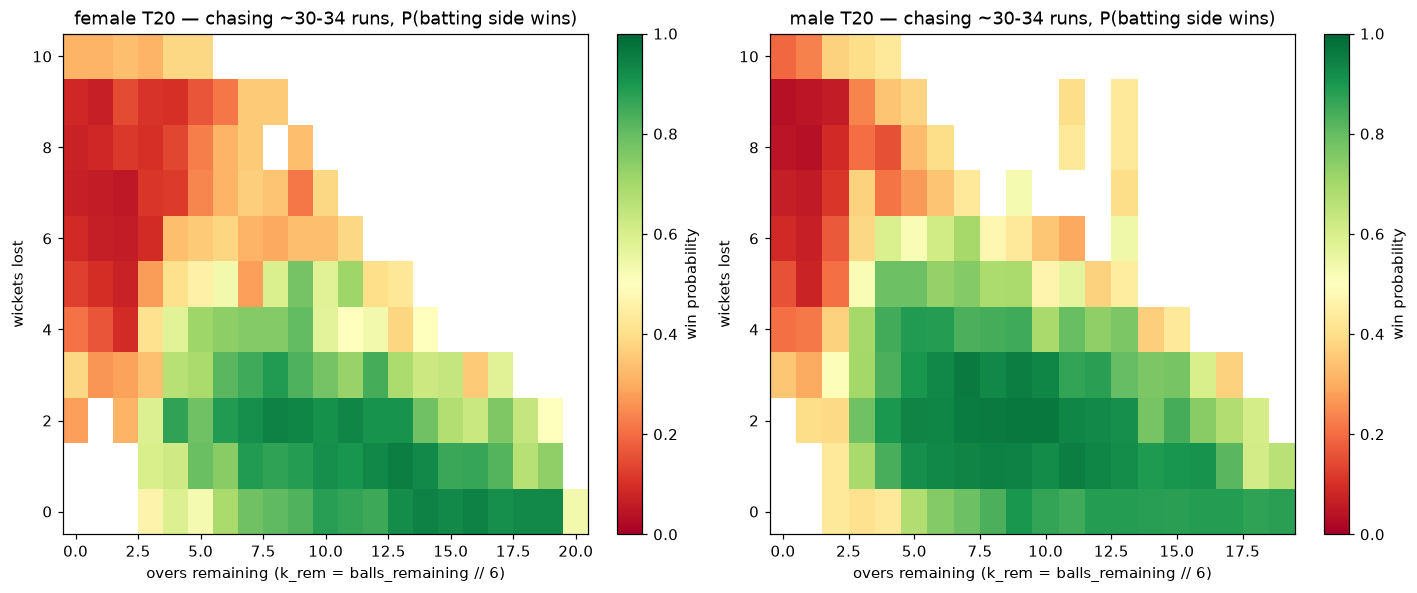

In [6]:
import sys as _sys
_sys.path.insert(0, "../data-collection")
from criiq_data.winprob import EmpiricalWinProb, _RR_BIN

REPRESENTATIVE_RR_BAND = 6  # ~30 runs required (band index = runs_required // 5)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, gender in zip(axes, ("female", "male")):
    model = EmpiricalWinProb.load("T20", gender)
    grid = model.grids["chase_full"]
    band = grid[grid["k_rr"] == REPRESENTATIVE_RR_BAND]
    pivot = band.pivot(index="k_wk", columns="k_rem", values="wp").reindex(index=range(0, 11))
    im = ax.imshow(pivot.values, cmap="RdYlGn", vmin=0, vmax=1, aspect="auto", origin="lower")
    ax.set_xlabel("overs remaining (k_rem = balls_remaining // 6)")
    ax.set_ylabel("wickets lost")
    ax.set_title(f"{gender} T20 — chasing ~{REPRESENTATIVE_RR_BAND * 5}-{REPRESENTATIVE_RR_BAND * 5 + 4} runs, "
                 f"P(batting side wins)")
    fig.colorbar(im, ax=ax, label="win probability", fraction=0.046)
plt.tight_layout()
plt.show()

**Reading this heatmap:** for a fixed, modest chase target (~30 runs needed), win probability climbs left-to-right (more overs left to find those runs) and drops top-to-bottom (fewer wickets in hand) — exactly the shape a cricket fan would expect, and a direct visual sanity-check that the shrinkage/backoff machinery above produced a sensible, monotonic surface rather than a noisy one. This is the model whose real held-out accuracy (§10 of `VALIDATION_REPORT.md`) is 77.4%/73.6% (female/male) at picking the eventual winner, with Brier scores of 0.156/0.173 against a ~0.25 naive baseline.

## 7. Summary

- Every `MODEL_FEATURES` column is a float except the one categorical `role_bucket`, one-hot encoded before the tree models see it.
- `vs_opp_*`/`venue_*`/`domestic_form_*` are the sparsest by design (most players have little or no specific history), which is exactly why they're shrunk toward a career baseline rather than left raw.
- No single feature correlates strongly with `batting_wpa`/`bowling_wpa` on its own — consistent with every holdout metric measured this session; a wide ensemble of weak, partially-redundant signals is doing the real work, not one dominant input.
- Bowling-containment stats and `age_years` were reproduced fresh above, not just quoted — the same temporal-holdout comparison the project uses everywhere else, run again live, in this notebook.
- The empirical win-probability model is a different, non-`MODEL_FEATURES` component: binned match-state frequencies with the same shrinkage-toward-a-prior discipline, backed off from fine to coarse to prior for sparse states, fit separately per (format, gender).

In [7]:
conn.close()